# Hola mundo de la difusión de video

El cuaderno anterior generaba puntos en el plano. Aquí cada dato es un video diminuto: 8 cuadros de $10\times 10$ píxeles con una pelota que cruza la pantalla en línea recta.

La idea clave cabe en una línea: **un video es un tensor más grande**. Tiene forma (cuadros, alto, ancho), y la difusión le suma y le quita ruido a todo el tensor de una vez. Como la red ve los 8 cuadros juntos, aprende también que la pelota de un cuadro tiene que aparecer un poco más adelante en el siguiente. Eso es la coherencia temporal.

Los pasos son los mismos de siempre: dataset, ruido, entrenamiento e inferencia.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML
from matplotlib import animation
from sklearn.neural_network import MLPRegressor

rng = np.random.default_rng(42)
NARANJA, PIZARRA = "#FF5900", "#262C34"


def tira(videos, titulos=None, alto=1.1):
    # Dibuja cada video como una fila de cuadros
    videos = np.asarray(videos)
    n, F = videos.shape[:2]
    fig, axes = plt.subplots(n, F, figsize=(alto * F, alto * n), squeeze=False)
    for i in range(n):
        for f in range(F):
            axes[i, f].imshow(videos[i, f], cmap="gray", vmin=-1, vmax=1)
            axes[i, f].set_xticks([])
            axes[i, f].set_yticks([])
            if i == 0:
                axes[i, f].set_title(f"cuadro {f}", fontsize=8)
        if titulos:
            axes[i, 0].set_ylabel(titulos[i], fontsize=8)
    plt.tight_layout()
    plt.show()


def reproducir(videos, intervalo=250):
    # Animación con varios videos lado a lado, cuadro por cuadro
    videos = np.asarray(videos)
    n, F = videos.shape[:2]
    fig, axes = plt.subplots(1, n, figsize=(1.6 * n, 1.9), dpi=80, squeeze=False)
    ims = []
    for ax, v in zip(axes[0], videos):
        ims.append(ax.imshow(v[0], cmap="gray", vmin=-1, vmax=1))
        ax.axis("off")
    titulo = fig.suptitle("")

    def dibujar(f):
        for im, v in zip(ims, videos):
            im.set_data(v[f])
        titulo.set_text(f"cuadro {f}")
        return ims

    anim = animation.FuncAnimation(fig, dibujar, frames=F, interval=intervalo)
    plt.close(fig)
    return HTML(anim.to_jshtml(default_mode="loop"))

## 1. El dataset

Una pelota es una mancha gaussiana. La hacemos gorda a propósito: con una pelota de uno o dos píxeles la señal es tan poca frente al ruido que la red tiende a generar pantallas negras. Fijamos dónde empieza y hacia dónde va (arriba, abajo, izquierda o derecha) y avanzamos un píxel por cuadro. Los píxeles van de $-1$ (negro) a $1$ (blanco). Todas las combinaciones que caben en la pantalla dan 64 videos.

forma del dataset: (64, 8, 10, 10)  (videos, cuadros, alto, ancho)
números por video: 800


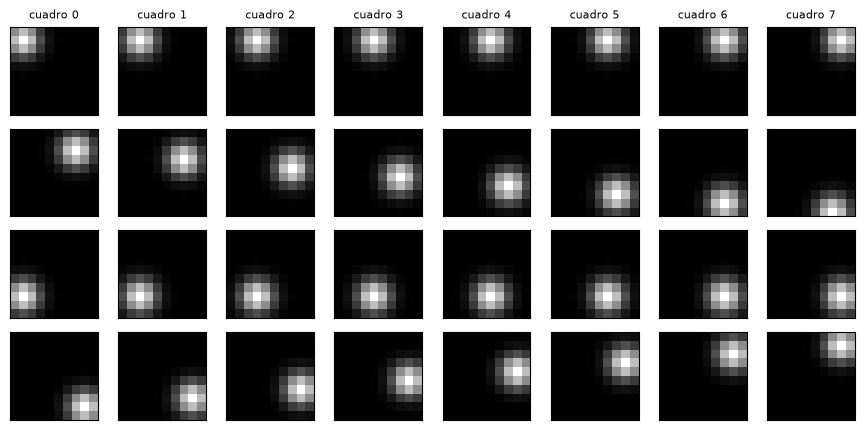

In [2]:
F, H, W = 8, 10, 10
fil, col = np.mgrid[0:H, 0:W]


def hacer_video(r, c, vr, vc):
    v = np.zeros((F, H, W))
    for f in range(F):
        v[f] = np.exp(-((fil - (r + vr * f)) ** 2 + (col - (c + vc * f)) ** 2) / (2 * 1.3**2))
    return v * 2 - 1


videos = []
for r in range(1, 9):
    for c in range(1, 9):
        for vr, vc in [(0, 1), (0, -1), (1, 0), (-1, 0)]:
            if 0 <= r + vr * (F - 1) < H and 0 <= c + vc * (F - 1) < W:
                videos.append(hacer_video(r, c, vr, vc))
videos = np.array(videos)
print("forma del dataset:", videos.shape, " (videos, cuadros, alto, ancho)")
print("números por video:", F * H * W)

ejemplos = videos[[0, 21, 40, 63]]
tira(ejemplos)

In [3]:
reproducir(ejemplos)

## 2. Ruido sobre el video completo

Usamos el mismo horario de 50 pasos del cuaderno anterior. El ruido cae sobre los 800 números a la vez: todos los cuadros se ensucian al mismo ritmo.

$$x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\epsilon$$

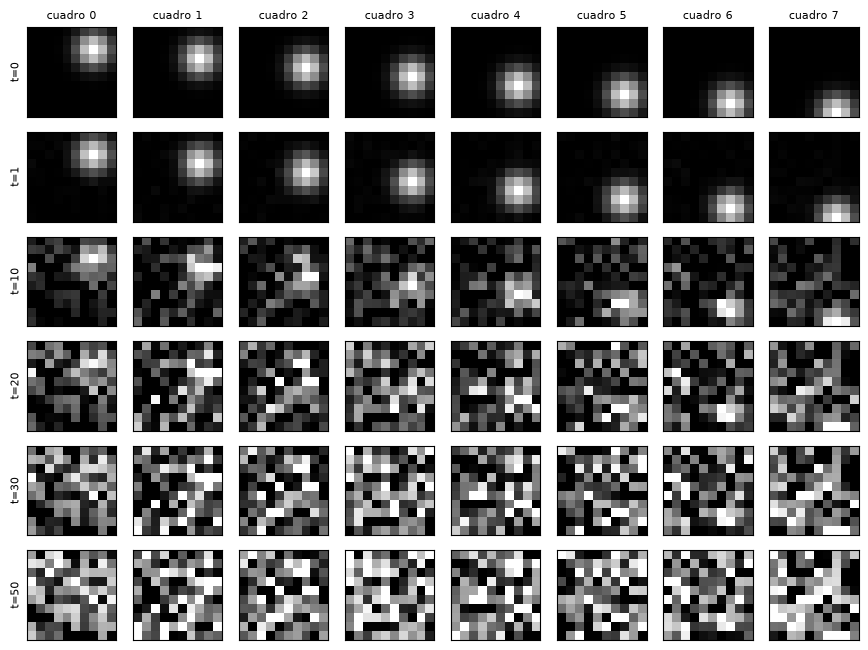

In [4]:
T = 50
betas = np.linspace(1e-3, 0.2, T)
alphas = 1 - betas
alpha_barra = np.cumprod(alphas)

X0 = videos.reshape(len(videos), -1)  # cada video aplanado: 800 números
N, D = X0.shape


def ensuciar(x0, t, eps):
    a = alpha_barra[t - 1][:, None]
    return np.sqrt(a) * x0 + np.sqrt(1 - a) * eps


eps = rng.standard_normal((1, D))
pasos = [1, 10, 20, 30, 50]
sucios = [ensuciar(X0[21:22], np.array([t]), eps).reshape(F, H, W) for t in pasos]
tira([videos[21], *sucios], titulos=["t=0", *[f"t={t}" for t in pasos]])

## 3. La tarea de la red

En el cuaderno del corazón la red adivinaba el ruido $\epsilon$. Aquí le pedimos algo equivalente que una red pequeña aprende más fácil: adivinar el **video limpio** $\hat x_0$. Casi todos los píxeles son fondo negro, y predecir "fondo negro con una pelota" es más sencillo que predecir 800 números de ruido.

Las dos versiones se convierten una en otra con la misma fórmula del ruido:

$$\hat\epsilon=\frac{x_t-\sqrt{\bar\alpha_t}\,\hat x_0}{\sqrt{1-\bar\alpha_t}}.$$

| entrada | salida esperada |
|---|---|
| video ruidoso $x_t$ (800 números) y $t$ | video limpio $x_0$ (800 números) |

In [5]:
def entrada(xt, t):
    tt = t[:, None] / T
    return np.c_[xt, tt, np.sin(np.pi * tt), np.cos(np.pi * tt)]


print("una entrada tiene", entrada(X0[:1], np.array([1])).shape[1], "números: 800 píxeles más 3 para el paso t")

una entrada tiene 803 números: 800 píxeles más 3 para el paso t


## 4. Entrenamiento

En cada iteración tomamos 512 videos al azar del dataset (con repetición), a cada uno le damos un $t$ y un ruido nuevos y hacemos una pasada de descenso por gradiente. Tarda alrededor de medio minuto.

iteración    0: pérdida = 0.2967
iteración  300: pérdida = 0.0232
iteración  600: pérdida = 0.0234
iteración  900: pérdida = 0.0225
iteración 1200: pérdida = 0.0230
iteración 1499: pérdida = 0.0215


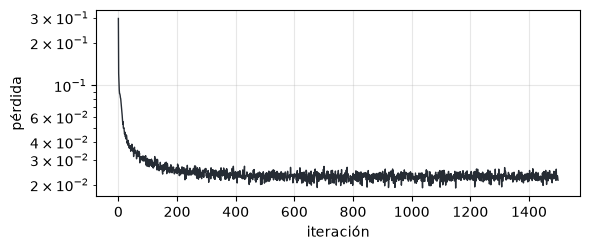

In [6]:
red = MLPRegressor(hidden_layer_sizes=(256, 256), learning_rate_init=1e-3, batch_size=64, random_state=42)
ITERACIONES, LOTE = 1500, 512
perdidas = []
for it in range(ITERACIONES):
    idx = rng.integers(0, N, LOTE)
    t = rng.integers(1, T + 1, LOTE)
    eps = rng.standard_normal((LOTE, D))
    red.partial_fit(entrada(ensuciar(X0[idx], t, eps), t), X0[idx])
    perdidas.append(red.loss_)
    if it % 300 == 0 or it == ITERACIONES - 1:
        print(f"iteración {it:>4}: pérdida = {red.loss_:.4f}")

fig, ax = plt.subplots(figsize=(6, 2.6))
ax.plot(perdidas, color=PIZARRA, lw=1)
ax.set_yscale("log")
ax.set_xlabel("iteración")
ax.set_ylabel("pérdida")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Antes de generar, una prueba: le damos a la red un video muy sucio ($t=30$) y vemos qué video limpio cree que había debajo.

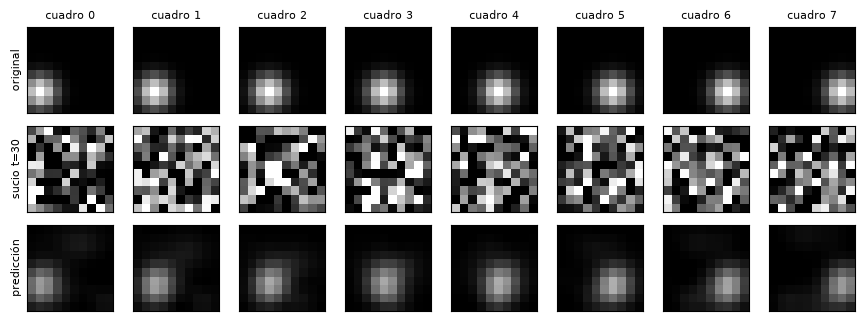

In [7]:
t = 30
sucio = ensuciar(X0[40:41], np.array([t]), rng.standard_normal((1, D)))
limpio = np.clip(red.predict(entrada(sucio, np.array([t]))), -1, 1)
tira([videos[40], sucio.reshape(F, H, W), limpio.reshape(F, H, W)],
     titulos=["original", f"sucio t={t}", "predicción"])

## 5. Inferencia paso a paso

Arrancamos con 8 videos de ruido puro y recorremos los 50 pasos hacia atrás. En cada paso la red predice el video limpio, lo convertimos en $\hat\epsilon$ y aplicamos la misma actualización del cuaderno anterior:

$$x_{t-1}=\frac{1}{\sqrt{\alpha_t}}\left(x_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\hat\epsilon\right)+\sqrt{\beta_t}\,z.$$

forma de la historia: (51, 8, 8, 10, 10)  (pasos, videos, cuadros, alto, ancho)


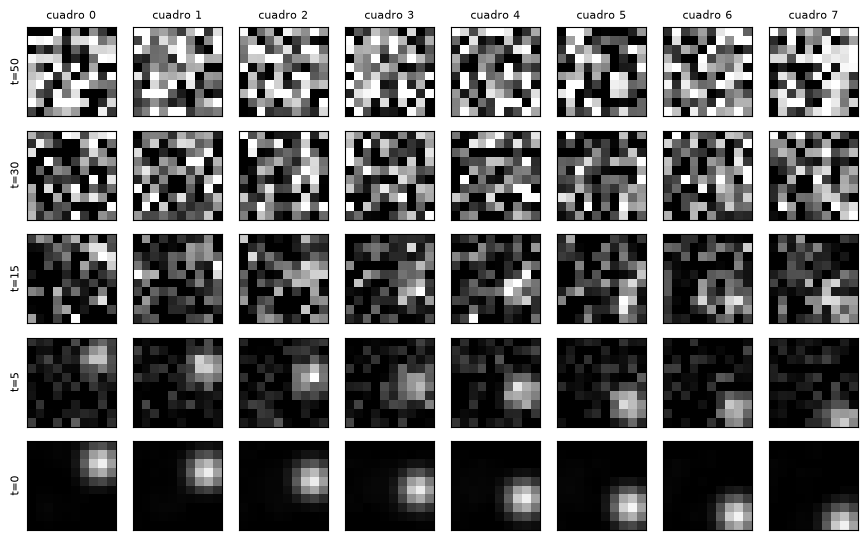

In [8]:
def paso_atras(x, t):
    x0_hat = np.clip(red.predict(entrada(x, np.full(len(x), t))), -1, 1)
    eps_hat = (x - np.sqrt(alpha_barra[t - 1]) * x0_hat) / np.sqrt(1 - alpha_barra[t - 1])
    media = (x - betas[t - 1] / np.sqrt(1 - alpha_barra[t - 1]) * eps_hat) / np.sqrt(alphas[t - 1])
    if t > 1:
        return media + np.sqrt(betas[t - 1]) * rng.standard_normal(x.shape)
    return media


x = rng.standard_normal((8, D))
historia = [x.copy()]
for t in range(T, 0, -1):
    x = paso_atras(x, t)
    historia.append(x.copy())
historia = np.array(historia).reshape(T + 1, 8, F, H, W)
print("forma de la historia:", historia.shape, " (pasos, videos, cuadros, alto, ancho)")

# El primer video generado, visto en varios momentos de la inferencia
momentos = [0, 20, 35, 45, 50]
tira([historia[k, 0] for k in momentos], titulos=[f"t={T - k}" for k in momentos])

La misma inferencia como animación. Cada cuadro de la animación es un paso $t$ y muestra los 8 cuadros del primer video a la vez: se ve cómo la pelota aparece en todos los cuadros al mismo tiempo, ya alineada en su recorrido.

In [9]:
fig, axes = plt.subplots(1, F, figsize=(1.3 * F, 1.7), dpi=80)
ims = [ax.imshow(historia[0, 0, f], cmap="gray", vmin=-1, vmax=1) for f, ax in enumerate(axes)]
for f, ax in enumerate(axes):
    ax.set_title(f"cuadro {f}", fontsize=8)
    ax.axis("off")
titulo = fig.suptitle("")


def dibujar(k):
    for f, im in enumerate(ims):
        im.set_data(historia[k, 0, f])
    titulo.set_text(f"inferencia, t = {T - k}")
    return ims


anim = animation.FuncAnimation(fig, dibujar, frames=T + 1, interval=120)
plt.close(fig)
HTML(anim.to_jshtml())

## 6. Los videos generados

Los 8 videos terminados, reproducidos en bucle.

In [10]:
generados = historia[-1]
reproducir(generados)

## 7. Revisión honesta

Dos preguntas para cada video generado: ¿la pelota se mueve de forma coherente?, ¿se parece a algún video del dataset? Para la primera seguimos el píxel más brillante de cada cuadro. Para la segunda buscamos el video de entrenamiento más cercano.

Con solo 64 videos de entrenamiento lo esperable es que la red reproduzca videos del dataset casi tal cual, y que alguno salga borroso o vacío. En un modelo real el dataset tiene millones de videos y la red combina lo aprendido en videos nuevos. El mecanismo es el mismo que se ve aquí.

video 0: (2,8) (3,8) (4,8) (5,8) (6,8) (7,8) (8,8) (9,8)   error con el video 23 del dataset: 0.0029
video 1: (6,8) (6,7) (6,6) (6,5) (6,4) (6,3) (6,2) (6,1)   error con el video 39 del dataset: 0.0104
video 2: (6,7) (6,6) (6,5) (6,4) (6,3) (6,2) (6,1) (6,0)   error con el video 38 del dataset: 0.0007
video 3: (6,7) (6,6) (6,5) (6,4) (6,3) (6,2) (6,1) (6,0)   error con el video 38 del dataset: 0.0095
video 4: (7,7) (6,7) (5,7) (4,7) (3,7) (2,7) (1,7) (0,7)   error con el video 49 del dataset: 0.0012
video 5: (8,3) (7,3) (6,3) (5,3) (4,3) (3,3) (2,3) (1,3)   error con el video 56 del dataset: 0.0119
video 6: (8,7) (7,7) (6,7) (5,7) (4,7) (3,7) (2,7) (1,7)   error con el video 61 del dataset: 0.0007
video 7: (5,7) (5,6) (5,5) (5,4) (5,3) (5,2) (5,1) (5,0)   error con el video 34 del dataset: 0.0020


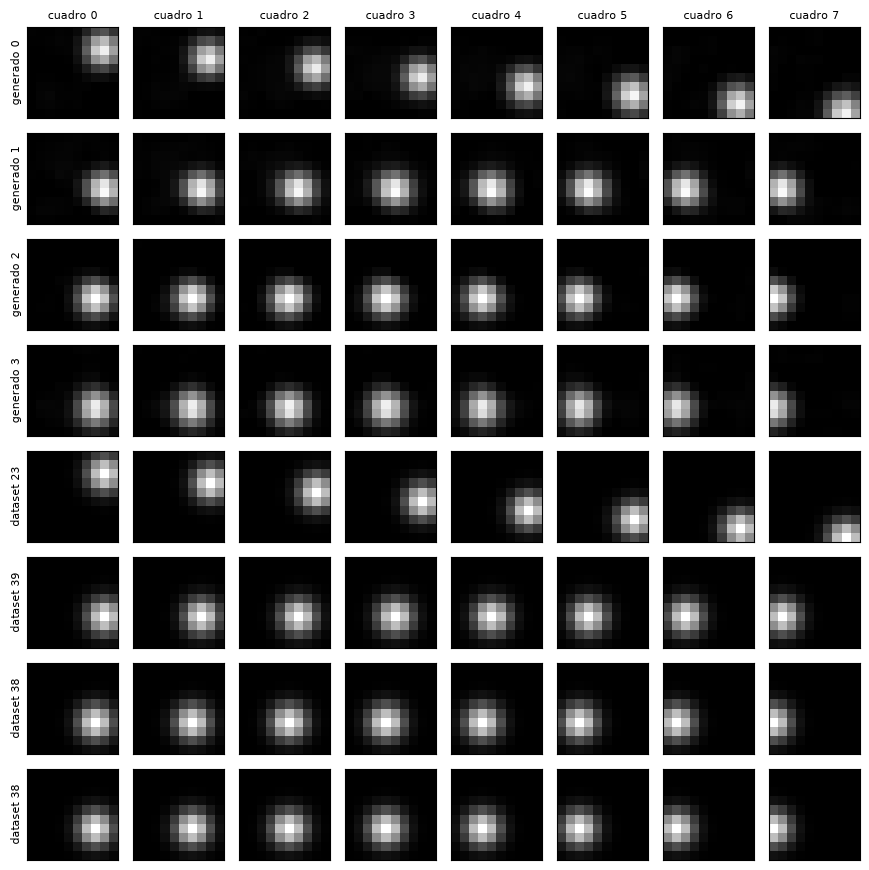

In [11]:
distancias = ((generados.reshape(8, 1, -1) - X0[None]) ** 2).mean(axis=2)
cercano = distancias.argmin(axis=1)

for i, v in enumerate(generados):
    brillo = v.reshape(F, -1).max(axis=1)
    pos = [divmod(int(cuadro.argmax()), W) for cuadro in v]
    if brillo.min() < 0.3:
        print(f"video {i}: sin pelota clara (brillo máximo {brillo.min():+.2f})")
        continue
    camino = " ".join(f"({r},{c})" for r, c in pos)
    print(f"video {i}: {camino}   error con el video {cercano[i]} del dataset: {distancias[i, cercano[i]]:.4f}")

tira(np.concatenate([generados[:4], videos[cercano[:4]]]),
     titulos=[f"generado {i}" for i in range(4)] + [f"dataset {j}" for j in cercano[:4]])